# CBE 130 Lab 4: Midterm Review

Numerical methods allow chemical engineers to predict process behavior when an analytical solution is difficult or unavailable. This review connects the Python and NumPy tools from the first three labs to first- and second-order ODE models that describe reactor concentrations and process responses.

## Learning Objectives

- Review basic Python syntax and commonly used NumPy functions.
- Compare the purpose, accuracy, and computational cost of common numerical ODE methods.
- Implement a numerical-method loop for a first-order reactor model.
- Use `solve_ivp` on fixed evaluation grids for first- and second-order ODEs.
- Validate numerical solutions against analytical solutions and interpret their errors.

## Setup

Run this cell once before working through the review. NumPy supports numerical calculations, Matplotlib creates plots, and SciPy provides `solve_ivp`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Part 1: Python and NumPy Reference

These worked cells collect the basic syntax and functions used throughout the semester. The examples use chemical engineering variables so that each operation has a physical interpretation.

### Question 1.1

Review variable assignment, lists, indexing, `if` statements, `for` loops, and functions using a short set of reactor temperature measurements in degrees Celsius.

In [ ]:
reactor_temperature_values = [68.0, 74.5, 82.0, 88.5]
temperature_limit = 80.0

print(f"First temperature = {reactor_temperature_values[0]:.1f} degrees C")
print(f"Last temperature = {reactor_temperature_values[-1]:.1f} degrees C")

for index, temperature_value in enumerate(reactor_temperature_values):
    if temperature_value > temperature_limit:
        status = "above the limit"
    else:
        status = "at or below the limit"
    print(f"Reading {index}: {temperature_value:.1f} degrees C is {status}.")

def celsius_to_kelvin(temperature_c):
    temperature_k = temperature_c + 273.15
    return temperature_k

temperature_k = celsius_to_kelvin(reactor_temperature_values[0])
print(f"First temperature = {temperature_k:.2f} K")

### Question 1.2

Review NumPy array creation, shapes, indexing, vectorized calculations, and common summary functions using batch concentration data in mol/L.

In [ ]:
t_values = np.linspace(0.0, 10.0, 6)
t_values_arange = np.arange(0.0, 10.0 + 2.0 / 2.0, 2.0)
zeros_array = np.zeros(5)
ones_matrix = np.ones((2, 3))
concentration_values = np.array([2.00, 1.64, 1.34, 1.10, 0.90, 0.74])
initial_concentration = concentration_values[0]
conversion_values = (initial_concentration - concentration_values) / initial_concentration

print(f"linspace time values = {t_values} min")
print(f"arange time values = {t_values_arange} min")
print(f"Zeros array = {zeros_array}")
print(f"Ones matrix =\n{ones_matrix}")
print(f"Concentration array shape = {concentration_values.shape}")
print(f"Third concentration = {concentration_values[2]:.2f} mol/L")
print(f"Conversion values = {conversion_values}")
print(f"Mean concentration = {np.mean(concentration_values):.3f} mol/L")
print(f"Minimum concentration = {np.min(concentration_values):.3f} mol/L")
print(f"Maximum concentration = {np.max(concentration_values):.3f} mol/L")

## Part 2: Purpose and Comparison of Numerical Methods

Numerical methods replace a continuous mathematical problem with a sequence of calculations that a computer can perform. They are useful when an analytical solution does not exist, is difficult to derive, or is less convenient than a numerical trajectory for a realistic model. A numerical result is an approximation, so step size, stability, accuracy, and computational cost must always be considered.

### Question 2.1

Use the following cheat sheet to compare four ODE methods. For all four methods, begin with a first-order ODE or system written as

$$
\frac{dY}{dt}=F(t,Y), \qquad Y(t_n)=Y_n,
$$

where $h=t_{n+1}-t_n$ is the step size. The equations below apply to either a scalar $y$ or a vector state $Y$.

### Forward Euler Method

Forward Euler uses the slope at the beginning of the interval. Starting from $(t_n,Y_n)$,

$$
\begin{aligned}
k_1 &= F(t_n,Y_n), \\
Y_{n+1} &= Y_n+h k_1.
\end{aligned}
$$

The method is first-order accurate, so reducing $h$ by a factor of two approximately reduces the global error by a factor of two. It is simple and inexpensive per step, but it can require a small step for acceptable accuracy and stability.

### Second-Order Runge-Kutta (Midpoint RK2) Method

Midpoint RK2 first estimates the state at the midpoint using an Euler half-step. It then uses the slope at that midpoint for the full update:

$$
\begin{aligned}
k_1 &= F(t_n,Y_n), \\
k_2 &= F\left(t_n+\frac{h}{2},\,Y_n+\frac{h}{2}k_1\right), \\
Y_{n+1} &= Y_n+h k_2.
\end{aligned}
$$

The method is second-order accurate, so reducing $h$ by a factor of two approximately reduces the global error by a factor of four. It uses two slope evaluations per step.

### Fourth-Order Runge-Kutta (RK4) Method

The classical RK4 method uses a weighted average of slopes at the starting point, two midpoint estimates, and the endpoint:

1. Use the starting slope $k_1$ to estimate a midpoint state and calculate $k_2$.
2. Use the midpoint slope $k_2$ to estimate another midpoint state and calculate $k_3$.
3. Use the new midpoint slope $k_3$ to estimate the endpoint state and calculate $k_4$.
4. Use a weighted average of $k_1$, $k_2$, $k_3$, and $k_4$ to calculate $Y_{n+1}$.

$$
\begin{aligned}
k_1 &= F(t_n,Y_n), \\
k_2 &= F\left(t_n+\frac{h}{2},\,Y_n+\frac{h}{2}k_1\right), \\
k_3 &= F\left(t_n+\frac{h}{2},\,Y_n+\frac{h}{2}k_2\right), \\
k_4 &= F(t_n+h,\,Y_n+h k_3), \\
Y_{n+1} &= Y_n+\frac{h}{6}\left(k_1+2k_2+2k_3+k_4\right).
\end{aligned}
$$

The method is fourth-order accurate, so reducing $h$ by a factor of two approximately reduces the global error by a factor of sixteen. It is usually much more accurate than Euler at the same step size, but requires four slope evaluations per step.

### Adaptive Runge-Kutta (RK45) Method

SciPy's `solve_ivp(method="RK45")` uses the Dormand-Prince 5(4) pair. It calculates several slopes and uses them to form both a fifth-order estimate $Y_{n+1}^{(5)}$ and a fourth-order estimate $Y_{n+1}^{(4)}$. If the scaled error is too large, RK45 rejects the step and retries with a smaller $h$. If the error is comfortably below the tolerance, it can increase $h$ for the next step. The accepted solution reported by `solve_ivp` uses the fifth-order estimate. This adaptivity makes RK45 convenient for models whose solution changes at different rates over time.

## Part 3: First-Order Batch-Reactor ODE

### Question 3.1

A first-order irreversible reaction $A\rightarrow B$ occurs in a constant-volume batch reactor. The concentration satisfies

$$
\frac{dC_A}{dt}=-kC_A, \qquad C_A(0)=2.0\ \text{mol/L},
$$

with $k=0.30\ \text{min}^{-1}$ over $0\leq t\leq10\ \text{min}$. The analytical solution is

$$C_A(t)=C_{A,0}e^{-kt}.$$

Use forward Euler with $\Delta t=0.5\ \text{min}$ and use `solve_ivp` at the same time values. Plot both numerical solutions with the analytical solution, print the final concentrations, and report the maximum absolute error of each numerical method.

The forward Euler update is

$$C_{A,i+1}=C_{A,i}+(-kC_{A,i})\Delta t.$$

In [ ]:
def F(t, CA, k):
    dconcentration_a_dt = -k * CA
    return dconcentration_a_dt

reaction_rate_constant = 0.30
initial_concentration_a = 2.0
t_initial = 0.0
t_final = 10.0
t_step = 0.5
t_values = np.arange(t_initial, t_final + t_step / 2.0, t_step)

CA_euler_values = np.zeros(len(t_values))
CA_euler_values[0] = initial_concentration_a

for index in range(len(t_values) - 1):
    t_current = t_values[index]
    CA_current = CA_euler_values[index]
    dCAdt = F(
        t_current, CA_current, reaction_rate_constant
    )
    next_concentration_a = CA_current + t_step * dCAdt
    CA_euler_values[index + 1] = next_concentration_a

solution = solve_ivp(
    F,
    (t_initial, t_final),
    [initial_concentration_a],
    method="RK45",
    t_eval=t_values,
    args=(reaction_rate_constant,),
)
solution_values = solution.y.T
CA_solve_ivp_values = solution_values[:, 0]
CA_analytical_values = (
    initial_concentration_a * np.exp(-reaction_rate_constant * t_values)
)

euler_error_values = np.abs(
    CA_euler_values - CA_analytical_values
)
solve_ivp_error_values = np.abs(
    CA_solve_ivp_values - CA_analytical_values
)

print(f"Final analytical concentration = {CA_analytical_values[-1]:.5f} mol/L")
print(f"Final Euler concentration = {CA_euler_values[-1]:.5f} mol/L")
print(f"Final solve_ivp concentration = {CA_solve_ivp_values[-1]:.5f} mol/L")
print(f"Euler maximum absolute error = {np.max(euler_error_values):.5f} mol/L")
print(f"solve_ivp maximum absolute error = {np.max(solve_ivp_error_values):.5f} mol/L")

plt.figure()
plt.plot(t_values, CA_analytical_values, label="Analytical")
plt.plot(t_values, CA_euler_values, "o--", label="Forward Euler")
plt.plot(t_values, CA_solve_ivp_values, "s-", label="solve_ivp RK45")
plt.title("First-Order Batch Reactor Concentration")
plt.xlabel("Time (min)")
plt.ylabel("Concentration of A (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

The `solve_ivp` result nearly overlaps the analytical curve. Forward Euler uses only the slope at the start of each interval, so its larger error is expected for the fixed $0.5$ min step.

## Part 4: Second-Order Reactor Temperature-Response ODE

### Question 4.1

After a feed-temperature disturbance, the temperature deviation of a jacketed reactor is approximated by the second-order model

$$
\frac{d^2T}{dt^2}+3\frac{dT}{dt}+2T=0, \qquad T(0)=10\ ^\circ\text{C}, \qquad \frac{dT}{dt}(0)=0\ ^\circ\text{C/min},
$$

for $0\leq t\leq5\ \text{min}$. The damping coefficient is $3.0\ \text{min}^{-1}$, the response coefficient is $2.0\ \text{min}^{-2}$, and $T$ is the reactor temperature deviation from its desired operating temperature. The analytical solution is

$$
T(t)=20e^{-t}-10e^{-2t}.
$$

Define $T_1=T$ and $T_2=dT/dt$. The equivalent first-order system is

$$
\frac{dT_1}{dt}=T_2, \qquad \frac{dT_2}{dt}=-3T_2-2T_1.
$$

Use an RK4 loop with $\Delta t=0.10\ \text{min}$ and use `solve_ivp` on the same fixed time grid. Plot both numerical solutions with the analytical solution, print the final temperature deviations, and report the RMSE and maximum absolute error for each numerical method.

For the state vector $Y_n=[T_n,(dT/dt)_n]^T$, the RK4 update is

$$
\begin{aligned}
k_1 &= F(t_n,Y_n), \\
k_2 &= F\left(t_n+\frac{\Delta t}{2},Y_n+\frac{\Delta t}{2}k_1\right), \\
k_3 &= F\left(t_n+\frac{\Delta t}{2},Y_n+\frac{\Delta t}{2}k_2\right), \\
k_4 &= F(t_n+\Delta t,Y_n+\Delta t k_3), \\
Y_{n+1} &= Y_n+\frac{\Delta t}{6}(k_1+2k_2+2k_3+k_4).
\end{aligned}
$$

Final analytical temperature deviation = 0.13430 degrees C
Final RK4 temperature deviation = 0.13474 degrees C
Final solve_ivp temperature deviation = 0.13434 degrees C


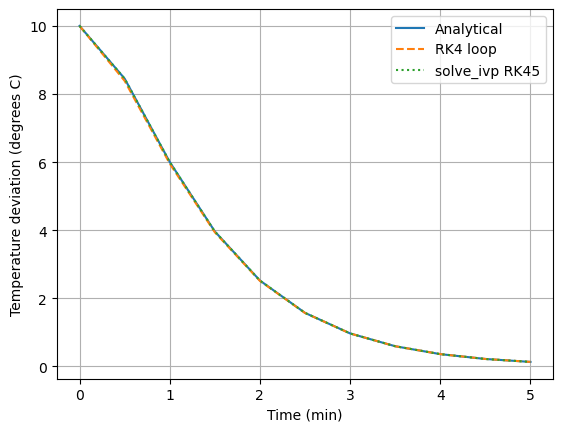

In [34]:
def F(t_current, state_values):
    T1 = state_values[0]
    T2 = state_values[1]
    return np.array([T2, -3 * T2 - 2 * T1])

def T_analytical(t_values):
    return 20.0 * np.exp(-t_values) - 10.0 * np.exp(-2.0 * t_values)

initial_temperature_deviation = 10.0
initial_temperature_rate = 0.0
t_initial = 0.0
t_final = 5.0
t_step = 0.50
t_values = np.arange(t_initial, t_final + t_step / 2.0, t_step)
IC = np.array([initial_temperature_deviation, initial_temperature_rate])
T_values_rk4 = np.zeros((len(t_values), 2))
T_values_rk4[0] = IC

for index in range(len(t_values) - 1):
    t_current = t_values[index]
    T_current = T_values_rk4[index]

    k1 = F(t_current, T_current)
    k2 = F(t_current + t_step / 2.0, T_current + t_step * k1 / 2.0)
    k3 = F(t_current + t_step / 2.0, T_current + t_step * k2 / 2.0)
    k4 = F(t_current + t_step, T_current + t_step * k3)
    T_next = T_current + (t_step / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
    T_values_rk4[index + 1] = T_next

solution = solve_ivp(
    F,
    (t_initial, t_final),
    IC,
    method="RK45",
    t_eval=t_values,
)
sol_rk4 = T_values_rk4[:, 0]
sol_solveivp = solution.y.T[:, 0]
sol_analytical = T_analytical(t_values)

print(f"Final analytical temperature deviation = {sol_analytical[-1]:.5f} degrees C")
print(f"Final RK4 temperature deviation = {sol_rk4[-1]:.5f} degrees C")
print(f"Final solve_ivp temperature deviation = {sol_solveivp[-1]:.5f} degrees C")

plt.figure()
plt.plot(t_values, sol_analytical, label="Analytical")
plt.plot(t_values, sol_rk4, "--", label="RK4 loop")
plt.plot(t_values, sol_solveivp, ":", label="solve_ivp RK45")
plt.xlabel("Time (min)")
plt.ylabel("Temperature deviation (degrees C)")
plt.legend()
plt.grid(True)
plt.show()